# **Robust Detection of AI-Generated Images Using Hybrid CNN-Frequency Fusion and Adversarial Training.**

the project proposes a hybrid architecture that integrates following branches:
* The **spatial branch** employs a convolutional neural network (CNN) to extract discriminative features from the raw image.
* The **frequency branch** processes the Fourier-transformed image to capture global periodic artifacts characteristic of AI-generated content.
* An **attention-based fusion module** then combines these heterogeneous features to form a robust representation.
* an **adversarial discriminator**—incorporated via a gradient reversal layer—enforces domain invariance by mitigating reliance on generator-specific artifacts.

>* Datasets: https://www.kaggle.com/datasets/alessandrasala79/ai-vs-human-generated-dataset | Labels: {Real(0), Fake(1)}
>* Loss: Binary Cross Entropy Loss `nn.BCEWithLogits()`
>* Optimizer: `torch.optim.SGD`
>* Evaluation Metrices: Accuracy, confusion matrix: `torchmetrics.ConfusionMatrix`
----------------------------------------




## 1. Import domain libraries and setup agnostic device

In [50]:
# Import required libraries
import torch
from torch import nn

#import torchvision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor
from sklearn.model_selection import train_test_split
import os
import subprocess
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

print(torch.__version__)
print(torchvision.__version__)

2.11.0+cpu
0.26.0+cpu


In [51]:
# Setup agnostic device
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    print("WARNING: No GPU found - training will be extremely slow (~10 hours per epoch on CPU).")
    print("In Colab: Runtime > Change runtime type > T4 GPU, then run all cells again.")
device

In Colab: Runtime > Change runtime type > T4 GPU, then run all cells again.


'cpu'

## 2. Get Dataset

Datasets: https://www.kaggle.com/datasets/alessandrasala79/ai-vs-human-generated-dataset | Labels: {Real(0), Fake(1)}

### 2.1 Data Preparation

In [52]:
import os
from google.colab import drive

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')
else:
    print("Drive already mounted.")

os.makedirs("/content/drive/MyDrive/AI_Project_Data", exist_ok=True)

Drive already mounted.


In [53]:
try:
  import kagglehub
except:
  !pip install kagglehub
  import kagglehub

os.environ["DISABLE_COLAB_CACHE"] = "true"
data_dir = kagglehub.dataset_download("alessandrasala79/ai-vs-human-generated-dataset")
print("Dataset downloaded to:", data_dir)
!ls "{data_dir}"

Dataset downloaded to: /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4
test.csv  test_data_v2	train.csv  train_data


In [54]:
import os
import pandas as pd
# TRAIN DATA
# Prepare train data and assign them to labels using pandas and link each csv to its image in train folder
train_folder = os.path.join(data_dir, "train_data")

train_csv_path = os.path.join(data_dir, "train.csv")
train_df_0 = pd.read_csv(train_csv_path)

# Map numeric labels to string labels
label_map = {0: "Human-Created Image", 1: "AI-Generated Image"}
train_df_0["label"] = train_df_0["label"].map(label_map)

# remove the repeatition of train_data in image path in csv file
def fix_image_path_train(file_name):
    file_name = file_name.strip()
    if file_name.startswith("train_data/"):
        file_name = file_name.replace("train_data/", "", 1)
    return os.path.join(train_folder, file_name)

train_df_0["image_path"] = train_df_0["file_name"].apply(fix_image_path_train)

# TEST DAT
# Prepare test data and assign absolute paths
test_folder = os.path.join(data_dir, "test_data_v2")
test_csv_path = os.path.join(data_dir, "test.csv")
test_df = pd.read_csv(test_csv_path)
def fix_image_path_test(file_name):
    file_name = str(file_name).strip()
    if file_name.startswith("test_data_v2/"):
        file_name = file_name.replace("test_data_v2/", "", 1)
    return os.path.join(test_folder, file_name)

test_df["image_path"] = test_df["id"].apply(fix_image_path_test)

In [55]:
from sklearn.model_selection import train_test_split

# Split Dataset
train_df_split, eval_df_split = train_test_split(
    train_df_0,
    test_size=0.5,  # eval is 20% of train data
    stratify=train_df_0["label"],  # for balance
    random_state=42  # to get fixed dataset
)

train_df, eval_df = train_test_split(
    train_df_split,
    test_size=0.2,  # eval is 20% of train data
    stratify=train_df_split["label"],  # for balance
    random_state=42  # to get fixed dataset
)

# length of train and eval dataset
print("Train size:", len(train_df))
print("Eval size:", len(eval_df))

# print out eval dataframe
eval_df.head()

Train size: 31980
Eval size: 7995


,Unnamed: 0,file_name,label,image_path
30695,30695,train_data/a385eb37c2c942e09d7b0eb168630f61.jpg,Human-Created Image,/root/.cache/kagglehub/datasets/alessandrasala...
31004,31004,train_data/e664cb206b9b4dbda9223ff99ce7e34b.jpg,AI-Generated Image,/root/.cache/kagglehub/datasets/alessandrasala...
6628,6628,train_data/0fa14fcc16304d93bdd6625ea8be9a2c.jpg,AI-Generated Image,/root/.cache/kagglehub/datasets/alessandrasala...
33197,33197,train_data/9eb03fb3c7dd43e8bf815564f5360bdc.jpg,Human-Created Image,/root/.cache/kagglehub/datasets/alessandrasala...
70626,70626,train_data/7445bab24e514eb6b9bb26694c897708.jpg,AI-Generated Image,/root/.cache/kagglehub/datasets/alessandrasala...


In [56]:
print(test_df.head())

                                                  id  \
0  test_data_v2/1a2d9fd3e21b4266aea1f66b30aed157.jpg   
1  test_data_v2/ab5df8f441fe4fbf9dc9c6baae699dc7.jpg   
2  test_data_v2/eb364dd2dfe34feda0e52466b7ce7956.jpg   
3  test_data_v2/f76c2580e9644d85a741a42c6f6b39c0.jpg   
4  test_data_v2/a16495c578b7494683805484ca27cf9f.jpg   

                                          image_path  
0  /root/.cache/kagglehub/datasets/alessandrasala...  
1  /root/.cache/kagglehub/datasets/alessandrasala...  
2  /root/.cache/kagglehub/datasets/alessandrasala...  
3  /root/.cache/kagglehub/datasets/alessandrasala...  
4  /root/.cache/kagglehub/datasets/alessandrasala...  


In [57]:
class_names = ["Human-Created Image", "AI-Generated Image"]
class_dict = {"Human-Created Image": 0 , "AI-Generated Image": 1}
class_names, class_dict

(['Human-Created Image', 'AI-Generated Image'],
 {'Human-Created Image': 0, 'AI-Generated Image': 1})

### 2.2 Data Exploration

### 2.3 Data cleaning and removing missing data

In [58]:
import os

def clean_split_data(df, split_name="Train"):
    """
    Check only the images referenced by the given split DataFrame.
    Removes rows with missing file names, labels, or image files.
    """

    original_size = len(df)

    # Remove rows with missing required values
    df = df.dropna(subset=["file_name", "label", "image_path"]).copy()

    # Check whether each referenced image actually exists
    file_exists = df["image_path"].map(os.path.isfile)

    # Count missing image files
    missing_files = (~file_exists).sum()

    # Keep only rows whose images exist
    df = df.loc[file_exists].copy()

    removed = original_size - len(df)

    print(f"\n{split_name} Data Consistency Check")
    print("-" * 40)
    print(f"Rows checked:   {original_size}")
    print(f"Rows removed:   {removed}")
    print(f"Rows remaining: {len(df)}")

    if removed == 0:
        print(f"✓ {split_name} data is clean.")
        print("  All required values and image files are present.")
    else:
        print(f"⚠ {split_name} data was cleaned.")
        print(f"  Missing image files: {missing_files}")
        print(f"  Invalid rows removed: {removed}")

    return df

In [59]:
train_df = clean_split_data(train_df, "Train")
eval_df = clean_split_data(eval_df, "Evaluation")


Train Data Consistency Check
----------------------------------------
Rows checked:   31980
Rows removed:   0
Rows remaining: 31980
✓ Train data is clean.
  All required values and image files are present.

Evaluation Data Consistency Check
----------------------------------------
Rows checked:   7995
Rows removed:   0
Rows remaining: 7995
✓ Evaluation data is clean.
  All required values and image files are present.


### 2.4 Visualizition of random images

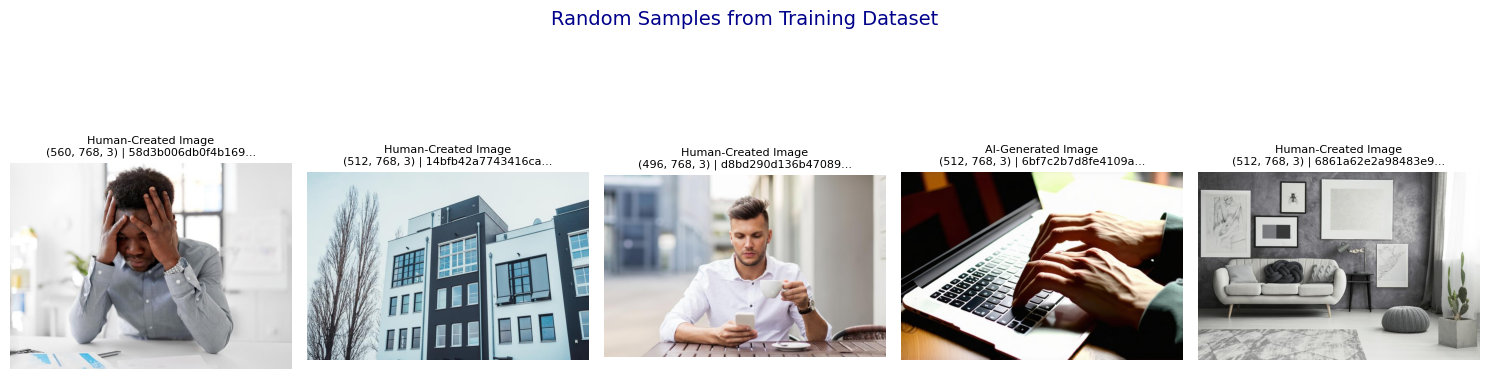

In [60]:
# show random images from the dataset
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt

# Get a random sample
samples = train_df.sample(5).reset_index(drop=True)
plt.figure(figsize=(15, 5))

# Show random images
plt.suptitle("Random Samples from Training Dataset", fontsize=14, color='darkblue')

for i in range(5):
    sample = samples.iloc[i]
    img = Image.open(sample["image_path"]).convert("RGB")
    img_array = np.asarray(img) # to show shape using numpy

    label = sample["label"]

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)

    file_name = os.path.basename(sample["image_path"]) # to get img path
    if len(file_name) > 20:
      file_name = file_name[:17] + "..."

    title = f"{label}\n{img_array.shape} | {file_name}"
    plt.title(title, fontsize=8, color='black')

    plt.axis("off")

plt.tight_layout()
plt.show()

array([[[ 52,  52,  52],
        [ 51,  51,  51],
        [ 50,  50,  50],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[ 53,  53,  53],
        [ 52,  52,  52],
        [ 52,  52,  52],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[ 54,  54,  54],
        [ 54,  54,  54],
        [ 54,  54,  54],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       ...,

       [[203, 203, 201],
        [215, 215, 213],
        [211, 211, 209],
        ...,
        [207, 208, 203],
        [207, 208, 203],
        [207, 208, 203]],

       [[206, 206, 204],
        [199, 199, 197],
        [180, 180, 178],
        ...,
        [207, 208, 203],
        [207, 208, 203],
        [206, 207, 202]],

       [[198, 198, 196],
        [170, 170, 168],
        [142, 142, 140],
        ...,
        [207, 208, 203],
        [206, 207, 202],
        [206, 207, 202]]], dtype=uint8)
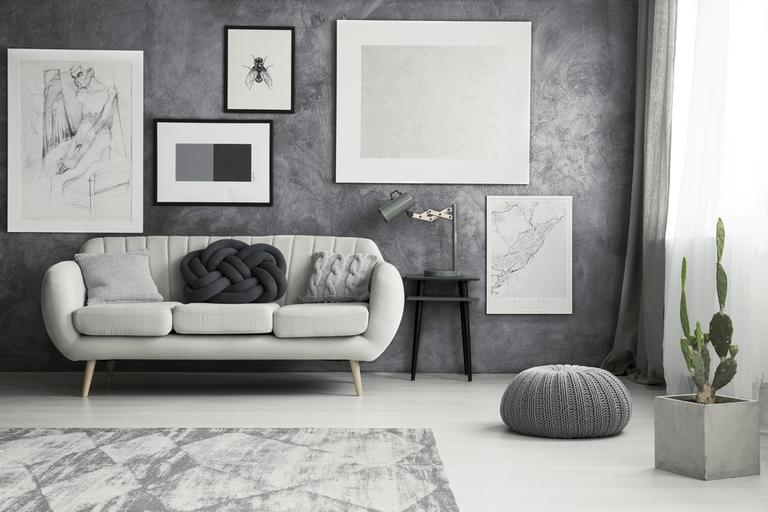

In [61]:
# Img as an array
img_array

## 3. Transform the data into tensors (numerical representation of images)
`torchvision.transforms` ->
`torch.utils.data.dataset` ->
`torch.utils.data.DataLoader`

In [62]:
import torch
import os
import pathlib
import random
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from PIL import Image
from typing import Tuple, Dict, List, Optional

In [63]:
# Data is not normalized/transformed yet
print(img_array.min(), img_array.max())

0 255


### 3.1 Transforming data with `torchvision.transforms`

In [64]:
train_transform_spatial = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

eval_transform_spatial = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

frequency_transform = transforms.Compose([
    transforms.Normalize(mean=[0.5], std=[0.5])
])

Before transformation
-------------------
img shape: (512, 768, 3)
img type: uint8


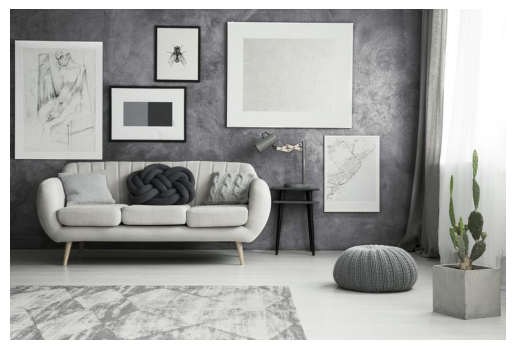

After transformation
-------------------
torch.Size([3, 224, 224])
torch.float32


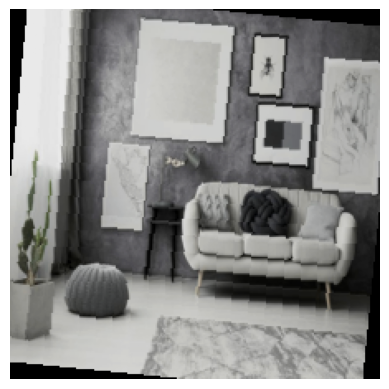

In [65]:
# Understanding our data

def unnormalize(tensor):
    mean = torch.tensor([0.5, 0.5, 0.5])
    std = torch.tensor([0.5, 0.5, 0.5])
    return tensor * std[:, None, None] + mean[:, None, None]

def show_tensor_image(tensor, ax=None):
    unnorm = unnormalize(tensor).permute(1, 2, 0).numpy()
    if ax is None:
        plt.imshow(unnorm)
        plt.axis('off')
    else:
        ax.imshow(unnorm)
        ax.axis('off')

# Before transformation
print("Before transformation\n-------------------")
print(f"img shape: {img_array.shape}")
print(f"img type: {img_array.dtype}")
#print(img_array)
plt.imshow(img_array)
plt.axis("off")
plt.show()

# After transformation
print("After transformation\n-------------------")
print(train_transform_spatial(img).shape)
print(train_transform_spatial(img).dtype)
show_tensor_image(train_transform_spatial(img))

In [66]:
def plot_transformed_images(df, image_path: str, transform, n=5, seed=42):
    """
    Randomly selects n images from a DataFrame and plots the original
    vs. the transformed version, along with label, shape, and file name.
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Sample from the dataframe
    samples = df.sample(n).reset_index(drop=True)

    for i in range(n):
        sample = samples.iloc[i]
        img_path = sample[image_path]
        label = sample["label"]

        with Image.open(img_path).convert("RGB") as img:
            img_array = np.asarray(img)
            transformed_img = transform(img)

            fig, ax = plt.subplots(1, 2, figsize=(8, 4))

            # Original image
            ax[0].imshow(img)
            ax[0].set_title(f"Original\n{img_array.shape}")
            ax[0].axis("off")

            # Transformed image (unnormalized)
            show_tensor_image(transformed_img, ax[1])
            ax[1].set_title(f"Transformed\n{tuple(transformed_img.shape[-2:])}")
            ax[1].axis("off")

            # Format file name
            file_name = os.path.basename(img_path)
            if len(file_name) > 20:
                file_name = file_name[:17] + "..."

            # Overall title
            fig.suptitle(f"{label} | {file_name}", fontsize=12, color='darkblue')
            plt.tight_layout()
            plt.show()

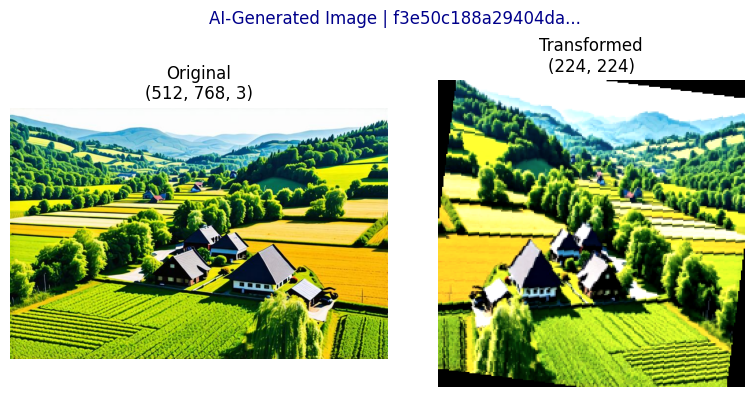

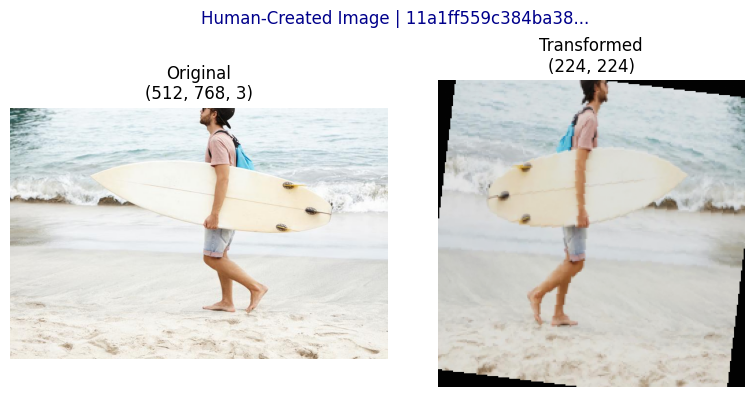

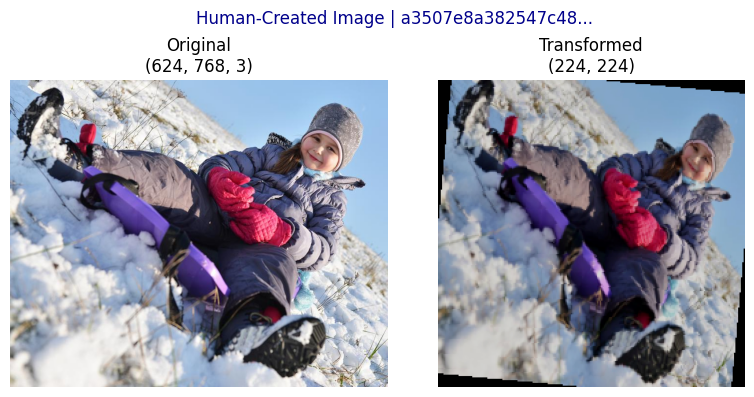

In [67]:
plot_transformed_images(
    df=train_df,
    image_path= "image_path",
    transform=train_transform_spatial,
    n=3,
    seed=None,
)

### 3.2 Create a custom dataset using `torch.utils.data.Dataset`

In [68]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image
import pandas as pd
from typing import Optional, Tuple
import numpy as np

class ImageFolderCustom(Dataset):
    def __init__(self,
                 dataframe: pd.DataFrame,
                 has_labels: bool = True,
                 spatial_transform: Optional[transforms.Compose] = None,
                 frequency_transform: Optional[transforms.Compose] = None,
                 class_to_idx: Optional[dict] = None):
        """
        Custom dataset for loading both spatial and frequency representations of images.
        """
        self.df = dataframe.reset_index(drop=True)
        self.has_labels = has_labels
        self.image_paths = self.df["image_path"].tolist()
        self.spatial_transform = spatial_transform
        self.frequency_transform = frequency_transform

        if self.has_labels:
            self.labels = self.df["label"].tolist()
            # Ensure consistent class mapping
            self.class_to_idx = class_to_idx or {
                "Human-Created Image": 0,
                "AI-Generated Image": 1
            }
            # Make sure df labels are in the map keys
            if not all(label in self.class_to_idx for label in self.df["label"].unique()):
                 print("Warning: Some labels in dataframe are not in class_to_idx!")
            self.classes = list(self.class_to_idx.keys())
        else:
            self.labels = None
            self.class_to_idx = None
            self.classes = None

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, torch.Tensor, int]:
        """
        Get spatial image tensor, frequency image tensor, and label index.
        """
        img_path = self.image_paths[index] # Use the input 'index'

        try:
            original_image = Image.open(img_path).convert('RGB')
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            raise IOError(f"Failed to load image: {img_path}") from e

        if self.spatial_transform:
            spatial_image_tensor = self.spatial_transform(original_image.copy())
        else:
            spatial_image_tensor = transforms.ToTensor()(original_image)

        frequency_image_tensor = self._to_frequency_domain(original_image.copy())


        # --- Get Label Index ---
        if self.has_labels:
            label_str = self.labels[index] # Use the input 'index'
            # Use the class_to_idx mapping defined in __init__
            if label_str in self.class_to_idx:
                 label_idx = self.class_to_idx[label_str]
            else:
                 # Handle unexpected labels
                 print(f"Warning: Unknown label '{label_str}' for image {img_path}. Assigning default label -1.")
                 label_idx = -1 # Or raise ValueError
                 # raise ValueError(f"Unknown label: {label_str}")
        else:
            label_idx = -1 # Or some placeholder for datasets without labels


        # --- Return Correctly Processed Tensors ---
        return spatial_image_tensor, frequency_image_tensor, label_idx


    def _to_frequency_domain(self, img_pil: Image.Image) -> torch.Tensor:
        """
        Convert the given PIL image (assumed RGB) to the frequency domain.
        Handles resizing, tensor conversion, FFT, averaging, log compression,
        and applies self.frequency_transform if provided.
        """
        # Standardize size (important for consistent FFT results)
        resize = transforms.Resize((224, 224)) # Match expected input size for models
        img_resized = resize(img_pil)

        # Convert PIL Image to numpy array -> torch Tensor -> permute -> normalize [0,1]
        img_np = np.array(img_resized)       # Shape: (H, W, C) e.g., (224, 224, 3)
        img_tensor = torch.from_numpy(img_np).float() # Shape: (H, W, C)
        img_tensor = img_tensor.permute(2, 0, 1) # Shape: (C, H, W) e.g., (3, 224, 224)
        img_tensor = img_tensor / 255.0          # Normalize pixel values to [0, 1]

        # Apply FFT (on H, W dimensions), shift zero frequency to center, get magnitude
        img_fft = torch.fft.fft2(img_tensor, dim=(-2, -1))
        img_fft_shifted = torch.fft.fftshift(img_fft, dim=(-2, -1))
        img_mag = torch.abs(img_fft_shifted) # Magnitude has shape (C, H, W)

        # Average magnitude across channels to get a single frequency map
        img_mag_avg = img_mag.mean(dim=0, keepdim=True) # Shape: (1, H, W)

        # Apply log compression for better visualization and potentially learning
        img_freq = torch.log1p(img_mag_avg) # log(1 + x), shape: (1, H, W)

        # Apply specific frequency domain transformations if provided
        # (e.g., normalization using mean=[0.5], std=[0.5] for the single channel)
        if self.frequency_transform:
            img_freq = self.frequency_transform(img_freq) # Expects [1, H, W] tensor

        return img_freq.float() # Ensure float tensor output

In [69]:
train_dataset = ImageFolderCustom(
    dataframe=train_df,
    has_labels=True,
    spatial_transform=train_transform_spatial,
    frequency_transform=frequency_transform,
    class_to_idx=class_dict
)

eval_dataset = ImageFolderCustom(
    dataframe=eval_df,
    has_labels=True,
    spatial_transform=eval_transform_spatial,
    frequency_transform=frequency_transform,
    class_to_idx=class_dict
)

In [70]:
# Display summary of train and test datasets
def display_dataset_info(dataset, name: str, show_paths: bool = True, num_paths: int = 10):
    print(f"\n{name} Summary")
    print("-" * (len(name) + 8))
    print(f"Total samples       : {len(dataset)}")
    if hasattr(dataset, "class_to_idx") and dataset.class_to_idx:
        print(f"Class-to-Index Map  : {dataset.class_to_idx}")
    if show_paths and hasattr(dataset, "image_paths"):
        sample_paths = dataset.image_paths[:num_paths]
        print(f"Sample image paths  :")
        for i, path in enumerate(sample_paths):
            print(f"  [{i+1}] {path}")

# Displaying both datasets
display_dataset_info(train_dataset, "Train Dataset")
display_dataset_info(eval_dataset, "Eval Dataset")


Train Dataset Summary
---------------------
Total samples       : 31980
Class-to-Index Map  : {'Human-Created Image': 0, 'AI-Generated Image': 1}
Sample image paths  :
  [1] /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/train_data/60af296e99d84c5c81722e993c6e6074.jpg
  [2] /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/train_data/33ed7a309a4243f6a882e1b4b4a533a8.jpg
  [3] /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/train_data/d95751daea834512b5830c4d0e879b11.jpg
  [4] /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/train_data/bca9caa2b02849e582f21beb770f46c7.jpg
  [5] /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/train_data/88401b4297954332814faf7aab2e28b4.jpg
  [6] /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/train_data/7c84

### 3.3 Display random images

In [71]:
#we will take random sample images and visualize them
random_sample_indexes = random.sample(range(len(train_dataset)), k=10)
random_sample_indexes

[15387, 26314, 9201, 10251, 11322, 8935, 30802, 16808, 14784, 29050]

In [72]:
def display_random_images(dataset: torch.utils.data.Dataset,
                          class_to_idx: dict = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):
    """
    Displays random sample images from a dataset with optional class names and shape info.
    """
    if n > 10:
        n = 10
        display_shape = False
        print("Capping number of images to 10 and hiding shape info for clarity.")

    if seed is not None:
        random.seed(seed)

    sample_indices = random.sample(range(len(dataset)), k=n)

    # Invert the class_to_idx mapping (index -> label)
    idx_to_class = {v: k for k, v in class_to_idx.items()} if class_to_idx else None

    fig, axes = plt.subplots(1, n, figsize=(n * 2, 4))

    for ax, idx in zip(axes, sample_indices):
        image, freq, label_idx = dataset[idx]

        # Convert label index to class name using idx_to_class
        if idx_to_class and label_idx in idx_to_class:
            label_str = idx_to_class[label_idx]  # Correct class name
        else:
            label_str = f"Label: {label_idx}"  # Fallback to numeric label if mapping fails

        # Show the image
        show_tensor_image(image, ax=ax)

        # Add shape info if display_shape is True
        if display_shape:
            label_str += f"\n{tuple(image.shape)}"

        # Set the title with class name and shape info (if enabled)
        ax.set_title(label_str, fontsize=10)

    plt.tight_layout()
    plt.show()

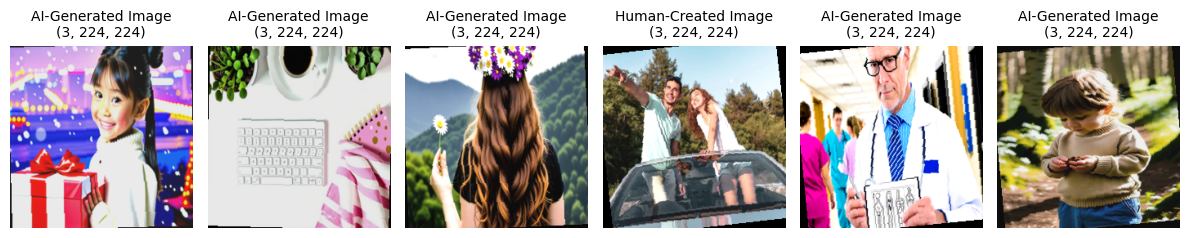

In [73]:
display_random_images(train_dataset,
                      class_to_idx=class_dict,
                      n=6,
                      display_shape=True,
                      seed=None
  )

### 3.4 Turn custom loaded images into Dataloaders

In [74]:
def custom_collate_fn(batch, target_size=(224, 224)):
    spatial_imgs, freq_imgs, labels = zip(*batch)

    # Stack spatial images (should already be same size from transform)
    spatial_imgs = torch.stack(spatial_imgs)

    # Resize frequency images to the target size
    freq_imgs_resized = []
    for img in freq_imgs:
        if img.shape[-2:] != target_size:
            img = img.unsqueeze(0)  # Add batch dim
            img = F.interpolate(img, size=target_size, mode='bilinear', align_corners=False)
            img = img.squeeze(0)
        freq_imgs_resized.append(img)

    freq_imgs = torch.stack(freq_imgs_resized)
    labels = torch.tensor(labels)

    return spatial_imgs, freq_imgs, labels

In [75]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()  # 2 on a Colab T4 runtime

train_dataloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=lambda batch: custom_collate_fn(batch, target_size=(224, 224))
)


eval_dataloader = DataLoader(
    dataset=eval_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=False
)
print(len(eval_dataloader), 500*32, len(train_dataloader))
train_dataloader, eval_dataloader,

250 16000 1000


(<torch.utils.data.dataloader.DataLoader at 0x7d97ab466490>,
 <torch.utils.data.dataloader.DataLoader at 0x7d97ce469350>)

In [76]:
spatial, frequency, labels = next(iter(train_dataloader))
spatial.shape, frequency.shape, labels.shape

(torch.Size([32, 3, 224, 224]),
 torch.Size([32, 1, 224, 224]),
 torch.Size([32]))

### 3.5 visualize n images of the spatial branch and frequency branch

In [77]:
def show_spatial_and_frequency(spatial_batch, frequency_batch, labels, class_dict, n=5):

    """
    visualize n images of the spatial branch and frequency branch
    """
    plt.figure(figsize=(n * 3, 6))

    for i in range(n):
        # Spatial image
        plt.subplot(2, n, i + 1)
        img = spatial_batch[i].permute(1, 2, 0)  # CxHxW → HxWxC
        img = img * 0.5 + 0.5  # Undo normalization [-1,1] → [0,1]
        plt.imshow(img)
        label_idx = int(labels[i])
        plt.title(f"Spatial\nLabel: {class_dict[label_idx]}")
        plt.axis("off")

        # Frequency image (magnitude only)
        plt.subplot(2, n, i + 1 + n)
        freq_img = frequency_batch[i]
        if freq_img.ndim == 3:
            freq_img = freq_img.mean(dim=0)  # Convert to single channel
        freq_img = freq_img / freq_img.max()  # Normalize for display
        plt.imshow(freq_img.cpu(), cmap="inferno")
        plt.title("Frequency")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

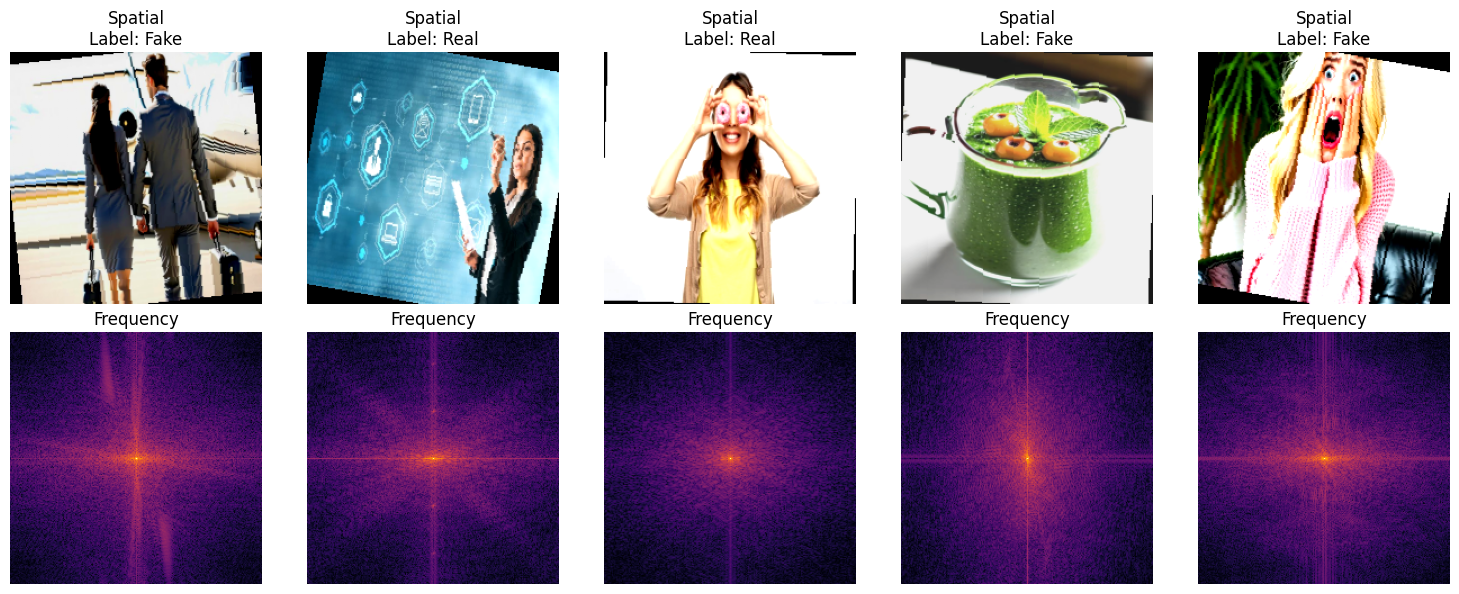

In [78]:
spatial_batch, frequency_batch, labels = next(iter(train_dataloader))
class_dict = {
    0: "Real",
    1: "Fake"
}
show_spatial_and_frequency(spatial_batch, frequency_batch, labels, class_dict, n=5)

## 4. Model 0: Hybrid Architecture

> Which integrate: **spatial branch** + **efrequency branch**.
> Combined via an attention-based fusion module. Followed by adversarial discriminator added.


In [79]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function

class GradientReversalLayerFn(Function):
    @staticmethod
    def forward(ctx, x, lambda_):
        ctx.lambda_ = lambda_
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        grad_input = grad_output.neg() * ctx.lambda_
        return grad_input, None

class BaseFeatureExtractor(nn.Module):
    def __init__(self, input_channels, feature_dim=256):
        super().__init__()

        self.conv1 = nn.Conv2d(input_channels, 64, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2) # 224 -> 112

        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2) # 112 -> 56

        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2, 2) # 56 -> 28

        # Added 4th block to preserve more local artifact information before global pooling
        self.conv4 = nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1)
        self.bn4 = nn.BatchNorm2d(512)
        self.pool4 = nn.MaxPool2d(2, 2) # 28 -> 14

        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))
        # Fixed syntax error: maps 512 channels from conv4 to feature_dim
        self.fc = nn.Linear(512, feature_dim)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        x = self.pool4(F.relu(self.bn4(self.conv4(x))))
        x = self.adaptive_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc(x)))
        return x

class SpatialBranch(BaseFeatureExtractor):
    def __init__(self, feature_dim=256):
        super().__init__(input_channels=3, feature_dim=feature_dim)

class FrequencyBranch(BaseFeatureExtractor):
    def __init__(self, feature_dim=256):
        super().__init__(input_channels=1, feature_dim=feature_dim)

# Renamed to accurately reflect what the math is doing
class GatedFusionModule(nn.Module):
    def __init__(self, feature_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.feature_dim = feature_dim

        self.att_weight_spatial = nn.Parameter(torch.ones(feature_dim))
        self.att_weight_freq = nn.Parameter(torch.ones(feature_dim))

        self.fc1 = nn.Linear(feature_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(hidden_dim, 1) # Final classification layer (AI vs Human)

    def forward(self, spatial_features, frequency_features):
        # Apply learned gating
        att_s = torch.sigmoid(self.att_weight_spatial)
        att_f = torch.sigmoid(self.att_weight_freq)
        spatial_weighted = spatial_features * att_s
        frequency_weighted = frequency_features * att_f

        combined_features = torch.cat((spatial_weighted, frequency_weighted), dim=1)

        x = self.dropout(F.relu(self.fc1(combined_features)))
        output = self.fc2(x)

        return output, x

class AdversarialDiscriminator(nn.Module):
    def __init__(self, input_size: int, hidden_dim: int = 64, num_domains: int = 1):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_dim)
        # Output matches number of domains/generators (e.g., 4 for Midjourney, DALL-E, SD, Real)
        self.fc2 = nn.Linear(hidden_dim, num_domains)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

class HybridModel(nn.Module):
    def __init__(self, feature_dim=256, fusion_hidden_dim=128, disc_hidden_dim=64, lambda_grl=0.1, use_adversarial=True, num_domains=1):
        super().__init__()
        self.use_adversarial = use_adversarial
        self.lambda_grl = lambda_grl

        self.spatial_branch = SpatialBranch(feature_dim)
        self.frequency_branch = FrequencyBranch(feature_dim)
        self.gated_fusion = GatedFusionModule(feature_dim, fusion_hidden_dim)

        if self.use_adversarial:
            self.domain_discriminator = AdversarialDiscriminator(fusion_hidden_dim, disc_hidden_dim, num_domains)

    def forward(self, spatial_input, frequency_input):
        spatial_features = self.spatial_branch(spatial_input)
        frequency_features = self.frequency_branch(frequency_input)

        main_task_output, intermediate_features = self.gated_fusion(spatial_features, frequency_features)

        if self.use_adversarial:
            reversed_features = GradientReversalLayerFn.apply(intermediate_features, self.lambda_grl)
            domain_task_output = self.domain_discriminator(reversed_features)
            return main_task_output, domain_task_output

        return main_task_output

# ==========================================
# Testing and Verification
# ==========================================

def get_fft_representation(rgb_batch):
    """
    Properly converts an RGB image batch to a 1-channel log-magnitude FFT spectrum.
    """
    # 1. Convert to grayscale using standard luminosity weights
    gray = 0.2989 * rgb_batch[:, 0:1, :, :] + 0.5870 * rgb_batch[:, 1:2, :, :] + 0.1140 * rgb_batch[:, 2:3, :, :]

    # 2. Compute 2D FFT
    fft = torch.fft.fft2(gray, norm="ortho")

    # 3. Shift zero-frequency component to center
    fft_shift = torch.fft.fftshift(fft, dim=(-2, -1))

    # 4. Get magnitude and apply log transform to normalize extreme values
    magnitude = torch.abs(fft_shift)
    log_magnitude = torch.log(magnitude + 1e-8)

    return log_magnitude


if __name__ == "__main__":
    feature_dim = 256
    fusion_hidden_dim = 128

    # Dummy spatial image [Batch, Channels, H, W]
    spatial_input = torch.randn(4, 3, 224, 224)

    # Generate proper frequency input from the spatial image
    frequency_input = get_fft_representation(spatial_input)

    print("--- Testing Baseline Model (No Discriminator) ---")
    baseline_model = HybridModel(use_adversarial=False)
    main_output = baseline_model(spatial_input, frequency_input)
    print("Main Task Output Shape:", main_output.shape) # Expected: [4, 1]

    print("\n--- Testing Domain-Adversarial Model ---")
    # Assuming 4 domains (e.g., Real, Midjourney, DALL-E, Stable Diffusion)
    adv_model = HybridModel(use_adversarial=True, lambda_grl=0.1, num_domains=4)
    main_output, domain_output = adv_model(spatial_input, frequency_input)

    print("Main Task Output Shape:", main_output.shape)     # Expected: [4, 1]
    print("Domain Task Output Shape:", domain_output.shape) # Expected: [4, 4]

--- Testing Baseline Model (No Discriminator) ---
Main Task Output Shape: torch.Size([4, 1])

--- Testing Domain-Adversarial Model ---
Main Task Output Shape: torch.Size([4, 1])
Domain Task Output Shape: torch.Size([4, 4])


## 5. Training loop

### 5.1 Train model

In [ ]:
from tqdm.auto import tqdm
import torch

def save_checkpoint(model, optimizer, epoch, batch_idx, loss, filename="checkpoint.pth"):
    checkpoint = {
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'epoch': epoch,
        'batch_idx': batch_idx,
        'loss': loss,
    }
    torch.save(checkpoint, filename)

def train_one_epoch(model, dataloader, optimizer, criterion_cls, criterion_adv, device, epoch, lambda_adv=1.0):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (spatial_imgs, frequency_imgs, labels) in tqdm(enumerate(dataloader), total=len(dataloader), desc=f"Epoch {epoch + 1}", unit="batch"):
        spatial_imgs = spatial_imgs.to(device)
        frequency_imgs = frequency_imgs.to(device)
        labels = labels.float().to(device)
        domain_labels = labels.clone()

        optimizer.zero_grad()

        class_output, adv_output = model(spatial_imgs, frequency_imgs)

        # Debug only for first batch
        if batch_idx == 0:
            print(f"[Epoch {epoch}] Sample Spatial Input Shape: {spatial_imgs.shape}")
            print(f"[Epoch {epoch}] class_output sample: {class_output[0].detach().cpu()}")
            print(f"[Epoch {epoch}] adv_output sample: {adv_output[0].detach().cpu()}")

        # Check for NaNs
        if torch.isnan(class_output).any() or torch.isinf(class_output).any():
            print(f"[Epoch {epoch}] NaN/Inf in class_output at batch {batch_idx}")
            continue

        loss_cls = criterion_cls(class_output.view(-1), labels)
        loss_adv = criterion_adv(adv_output.view(-1), domain_labels)
        loss = loss_cls + lambda_adv * loss_adv

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Accuracy
        preds = (torch.sigmoid(class_output) > 0.5).float()
        correct += (preds.view(-1) == labels).sum().item()
        total += labels.size(0)

        if batch_idx % 5 == 0:
            print(f"[Batch {batch_idx}] Loss: {loss.item():.4f} Acc: {correct/total:.4f}")
            save_checkpoint(model, optimizer, epoch, batch_idx, loss, filename="checkpoint.pth")

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = correct / total
    print(f"\n[Epoch {epoch} training Summary] Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}\n")

    return epoch_loss, epoch_acc

### 5.2 Eval model

In [ ]:
def eval_one_epoch(model, dataloader, criterion_cls, device, epoch):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_idx, (spatial_imgs, frequency_imgs, labels) in tqdm(enumerate(dataloader),
                                                              total=len(dataloader),
                                                              desc=f"Eval Epoch {epoch}",
                                                              unit="batch"):
            spatial_imgs = spatial_imgs.to(device)
            frequency_imgs = frequency_imgs.to(device)
            labels = labels.float().to(device)

            class_output, _ = model(spatial_imgs, frequency_imgs)

            loss_cls = criterion_cls(class_output.view(-1), labels)
            running_loss += loss_cls.item()

            preds = (torch.sigmoid(class_output) > 0.5).float()
            correct += (preds.view(-1) == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = correct / total
    print(f"[Epoch {epoch} | Evaluation] Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.4f}%\n")

    return epoch_loss, epoch_acc

### 5.3 train and eval model and save best model

In [ ]:
from tqdm.auto import tqdm
import copy
import torch

def train_model(model: torch.nn.Module,
                train_dataloader,
                val_dataloader,
                optimizer,
                criterion_cls,
                criterion_adv,
                epochs: int,
                device: torch.device,
                lambda_adv: float = 1.0,
                start_epoch: int = 0):

    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    results = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in tqdm(range(start_epoch, start_epoch + epochs), desc="Training Progress"):
        # Training step
        train_loss, train_acc = train_one_epoch(
            model=model,
            dataloader=train_dataloader,
            optimizer=optimizer,
            criterion_cls=criterion_cls,
            criterion_adv=criterion_adv,
            device=device,
            epoch=epoch,
            lambda_adv=lambda_adv
        )

        # Evaluation step
        val_loss, val_acc = eval_one_epoch(
            model=model,
            dataloader=val_dataloader,
            criterion_cls=criterion_cls,
            device=device,
            epoch=epoch
        )

        # Save best model based on validation accuracy
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), "/content/drive/MyDrive/AI_Project_Data/best_hybrid_model.pth")
            print(f"Saved new best model at epoch {epoch} with val acc: {val_acc:.4f}")

        # Save regular checkpoint every 5 epochs
        if (epoch + 1) % 5 == 0:
            torch.save(model.state_dict(), f"checkpoint_epoch_{epoch+1}.pth")
            print(f"Saved checkpoint at epoch {epoch+1}")

        # Append results
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["val_loss"].append(val_loss)
        results["val_acc"].append(val_acc)

    # Load best model weights at the end
    model.load_state_dict(best_model_wts)

    return results

### 5.4 training


In [ ]:
from timeit import default_timer as timer
from google.colab import files

# 1. Set seeds for reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# 2. Define training hyperparameters
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
LAMBDA_ADV = 0.5

# 3. Instantiate hybrid model and move to device
hybrid_model = HybridModel(feature_dim=feature_dim, fusion_hidden_dim=fusion_hidden_dim, lambda_grl=1.0).to(device)

# 4. Define loss functions
criterion_cls = nn.BCEWithLogitsLoss()      # Binary classification loss
criterion_adv = nn.BCEWithLogitsLoss()      # Domain/adversarial loss

# 5. Optimizer
optimizer = torch.optim.SGD(hybrid_model.parameters(), lr=LEARNING_RATE, momentum=0.9)

# 6. Define accuracy metric
def acc_fn(y_true, y_pred):
    y_pred_label = (torch.sigmoid(y_pred) > 0.5).float()
    correct = torch.eq(y_true.view(-1), y_pred_label.view(-1)).sum().item()
    return correct / len(y_true)

# 7. Start training timer
start_time = timer()

# 8. Train the model
results = train_model(model=hybrid_model,
                      train_dataloader=train_dataloader,
                      val_dataloader=eval_dataloader,
                      optimizer=optimizer,
                      criterion_cls=criterion_cls,
                      criterion_adv=criterion_adv,
                      epochs=NUM_EPOCHS,
                      device=device,
                      lambda_adv=LAMBDA_ADV)

torch.save({
    "model_state_dict": hybrid_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "lambda_adv": LAMBDA_ADV,
    "feature_dim": feature_dim,
    "fusion_hidden_dim": fusion_hidden_dim,
}, "hybrid_model.pth")

files.download("hybrid_model.pth")

print("Model saved as hybrid_model.pth")

# 10. End timer and print duration
end_time = timer()
print(f"Total training time: {end_time - start_time:.2f} seconds.")

Training Progress:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/1000 [00:00<?, ?batch/s]

[Epoch 0] Sample Spatial Input Shape: torch.Size([32, 3, 224, 224])
[Epoch 0] class_output sample: tensor([0.0253])
[Epoch 0] adv_output sample: tensor([-0.0954])
[Batch 0] Loss: 1.0478 Acc: 0.5000
[Batch 5] Loss: 1.0479 Acc: 0.4479
[Batch 10] Loss: 1.0467 Acc: 0.5142
[Batch 15] Loss: 1.0505 Acc: 0.5254
[Batch 20] Loss: 1.0342 Acc: 0.5402
[Batch 25] Loss: 1.0261 Acc: 0.5577
[Batch 30] Loss: 1.0244 Acc: 0.5645
[Batch 35] Loss: 1.0025 Acc: 0.5790
[Batch 40] Loss: 1.0331 Acc: 0.5838
[Batch 45] Loss: 0.9944 Acc: 0.5904
[Batch 50] Loss: 0.9923 Acc: 0.5956
[Batch 55] Loss: 0.9820 Acc: 0.6083
[Batch 60] Loss: 0.9992 Acc: 0.6168
[Batch 65] Loss: 0.9398 Acc: 0.6269
[Batch 70] Loss: 0.9885 Acc: 0.6329
[Batch 75] Loss: 0.9565 Acc: 0.6390
[Batch 80] Loss: 0.9528 Acc: 0.6447
[Batch 85] Loss: 0.9670 Acc: 0.6490
[Batch 90] Loss: 0.9519 Acc: 0.6521
[Batch 95] Loss: 0.9928 Acc: 0.6585
[Batch 100] Loss: 0.9293 Acc: 0.6652
[Batch 105] Loss: 0.9165 Acc: 0.6686
[Batch 110] Loss: 0.9577 Acc: 0.6723
[Batch 1

Eval Epoch 0:   0%|          | 0/250 [00:00<?, ?batch/s]

[Epoch 0 | Evaluation] Loss: 0.3487 | Accuracy: 0.8742%

Saved new best model at epoch 0 with val acc: 0.8742


...

Eval Epoch 19:   0%|          | 0/250 [00:00<?, ?batch/s]

[Epoch 19 | Evaluation] Loss: 0.1972 | Accuracy: 0.9255%

Saved checkpoint at epoch 20


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved as hybrid_model.pth
Total training time: 5267.99 seconds.


In [ ]:
results

{'train_loss': [0.769383023917675,
  0.5759486837387084,
  0.4864298473149538,
  0.4619271666407585,
  0.44293996535241603,
  0.4239829002469778,
  0.4031800759360194,
  0.40410772006958723,
  0.3872186145968735,
  0.38393065259605647,
  0.37101557548344133,
  0.36417154216021297,
  0.36129902724549173,
  0.35150781711935997,
  0.3471993789300323,
  0.33465568160265685,
  0.33081862819194796,
  0.324508773162961,
  0.3264521181806922,
  0.3160127297341824],
 'train_acc': [0.7956222639149468,
  0.8474358974358974,
  0.86776110068793,
  0.8731394621638524,
  0.8794559099437148,
  0.8873671044402752,
  0.8933708567854909,
  0.8909943714821763,
  0.8976860537836148,
  0.8964665415884928,
  0.9012507817385866,
  0.9029706066291432,
  0.9042839274546591,
  0.9074108818011257,
  0.9100687929956223,
  0.9120075046904316,
  0.9142589118198874,
  0.9149468417761101,
  0.9136335209505941,
  0.9162288930581614],
 'val_loss': [0.34870927047729494,
  0.28591327494382857,
  0.26932996046543123,
  0.2

In [ ]:
results.keys()

dict_keys(['train_loss', 'train_acc', 'val_loss', 'val_acc'])

In [ ]:
import matplotlib.pyplot as plt
from typing import Dict, List

def plot_loss_curves(results: Dict[str, List[float]]):
    """ Plots training curves of results dictionary with train and validation loss and accuracy. """

    # Get the loss values of the results dictionary (training and validation)
    train_loss = results["train_loss"]
    val_loss = results["val_loss"]

    # Get the accuracy values of the results dictionary (training and validation)
    train_acc = results["train_acc"]
    val_acc = results["val_acc"]

    # Figure out how many epochs there are
    epochs = range(len(train_acc))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot the losses
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label="Train Loss")
    plt.plot(epochs, val_loss, label="Validation Loss")
    plt.title("Loss Over Epochs")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    # Plot the accuracies
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label="Train Accuracy")
    plt.plot(epochs, val_acc, label="Validation Accuracy")
    plt.title("Accuracy Over Epochs")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    # Show the plot
    plt.tight_layout()
    plt.show()

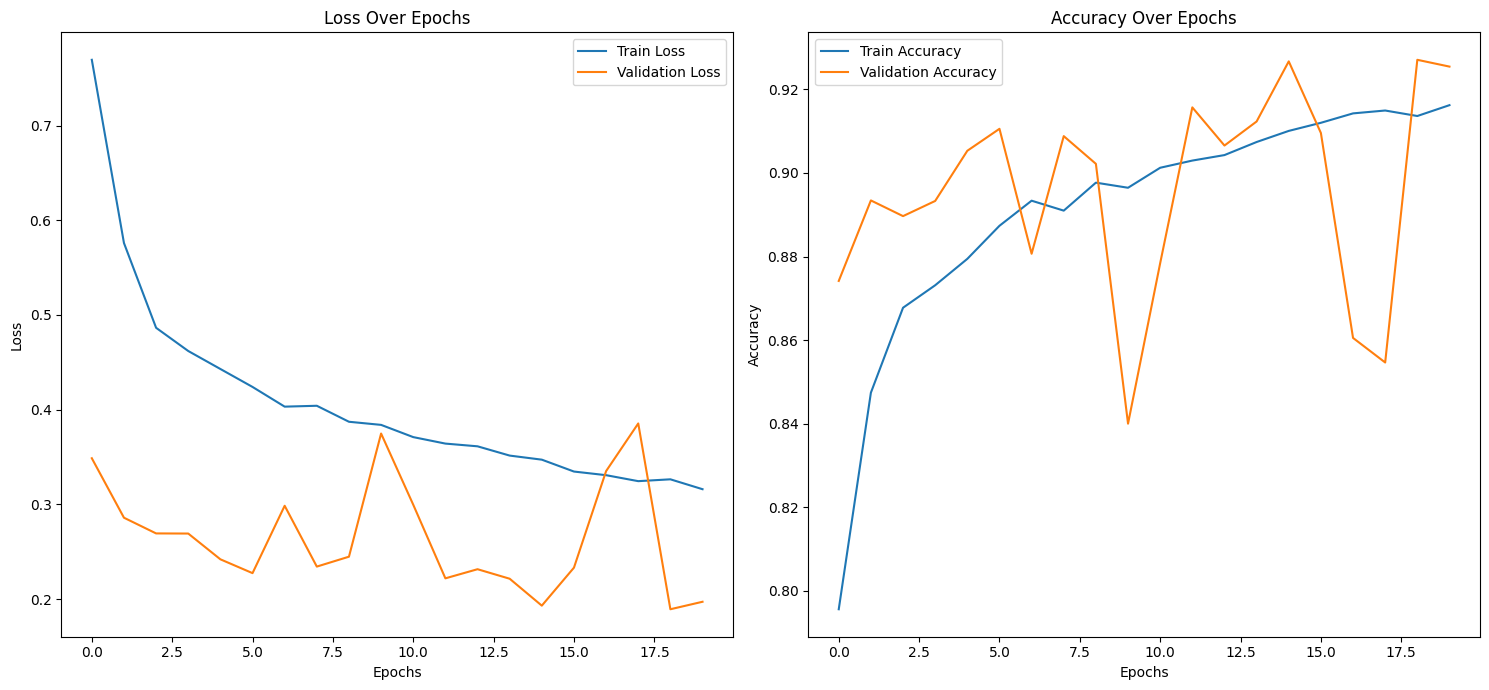

In [ ]:
plot_loss_curves(results)

## 6. Hybrid model summary

In [ ]:
#install torchinfo, import if it is available OMG this isssssss smooth
try:
  import torchinfo
except:
  !pip install torchinfo
  import torchinfo
from torchinfo import summary

In [ ]:
summary(hybrid_model,
        input_data=(torch.randn(4, 3, 224, 224, device=device),  # spatial_input
                    torch.randn(4, 1, 224, 224, device=device)),  # frequency_input
        col_names=["input_size", "output_size", "num_params", "trainable"],
        depth=3)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
HybridModel                              [4, 3, 224, 224]          [4, 1]                    --                        True
├─SpatialBranch: 1-1                     [4, 3, 224, 224]          [4, 256]                  --                        True
│    └─Conv2d: 2-1                       [4, 3, 224, 224]          [4, 64, 224, 224]         1,792                     True
│    └─BatchNorm2d: 2-2                  [4, 64, 224, 224]         [4, 64, 224, 224]         128                       True
│    └─MaxPool2d: 2-3                    [4, 64, 224, 224]         [4, 64, 112, 112]         --                        --
│    └─Conv2d: 2-4                       [4, 64, 112, 112]         [4, 128, 112, 112]        73,856                    True
│    └─BatchNorm2d: 2-5                  [4, 128, 112, 112]        [4, 128, 112, 112]        256                       True
│    

## 7. Plot the loss and accutacy curves

## 8. Confusion Matrix

In [80]:
try:
  import torchmetrics
except:
  !pip install -q torchmetrics
  import torchmetrics

try:
  import mlxtend
except:
  !pip install -q mlxtend
  import mlxtend

In [81]:
!ls -lh /content/hybrid_model.pth

ls: cannot access '/content/hybrid_model.pth': No such file or directory


In [34]:
import torch

# 1. Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 2. Initialize the model architecture
feature_dim = 256
fusion_hidden_dim = 128
model = HybridModel(feature_dim=feature_dim, fusion_hidden_dim=fusion_hidden_dim, lambda_grl=1.0)

# 3. Load the full checkpoint file
checkpoint = torch.load('/content/hybrid_model.pth', map_location=device)

# 4. Extract only the model weights and load them
model.load_state_dict(checkpoint['model_state_dict'])

# 5. Move to device and set to eval mode
model.to(device)
model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [35]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in eval_dataloader:
        spatial, frequency, labels = batch

        spatial = spatial.to(device)
        frequency = frequency.to(device)
        labels = labels.to(device)

        # Get model outputs (logits)
        outputs = model(spatial, frequency)[0]

        # CORRECTED PRED LOGIC: Sigmoid + 0.5 threshold for Binary Classification
        preds = (torch.sigmoid(outputs) > 0.5).int()

        # Flatten and move to CPU/numpy
        all_preds.extend(preds.view(-1).cpu().numpy())
        all_labels.extend(labels.view(-1).cpu().numpy())

                   precision    recall  f1-score   support

Human-Created (0)       0.93      0.92      0.93      3998
 AI-Generated (1)       0.92      0.93      0.93      3997

         accuracy                           0.93      7995
        macro avg       0.93      0.93      0.93      7995
     weighted avg       0.93      0.93      0.93      7995



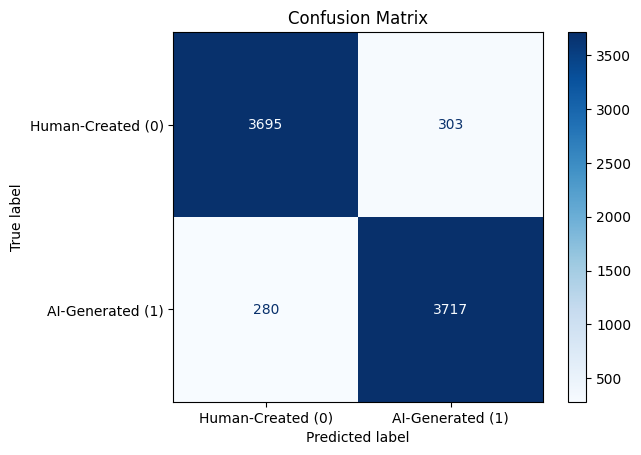

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

cm = confusion_matrix(all_labels, all_preds)
display_labels = ["Human-Created (0)", "AI-Generated (1)"]
print(classification_report(all_labels, all_preds, target_names=display_labels))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot(cmap=plt.cm.Blues, values_format='d')

plt.title("Confusion Matrix")
plt.show()

## 9. Making a prediction on a custom image

In [82]:
import torch
import matplotlib.pyplot as plt
from typing import List
from PIL import Image

def custom_image_prediction(model: torch.nn.Module,
                             image_path: str,
                             actual_label: str = None,  # Added actual label parameter
                             class_names: List[str] = None,
                             transform_spatial=None,
                             transform_frequency=None,
                             device=torch.device('cpu')):

    # 1. Read image with PIL
    target_image = Image.open(image_path).convert('RGB')

    # 2. Apply transformations
    spatial_image = transform_spatial(target_image) if transform_spatial else target_image
    frequency_image = transform_frequency(target_image) if transform_frequency else target_image

    # 3. Move model to device
    model = model.to(device)

    # 4. Inference
    model.eval()
    with torch.inference_mode():
        spatial_batch = spatial_image.unsqueeze(0).to(device)
        frequency_batch = frequency_image.unsqueeze(0).to(device)

        class_output, _ = model(spatial_batch, frequency_batch)

        pred_prob = torch.sigmoid(class_output).squeeze()
        pred_label = torch.round(pred_prob).int().item()

        # Calculate confidence for the chosen class
        confidence = pred_prob if pred_label == 1 else 1.0 - pred_prob

    # 5. Prepare image for plotting
    display_image = spatial_image.permute(1, 2, 0).cpu()
    display_image = (display_image * 0.5) + 0.5
    display_image = display_image.clamp(0, 1)

    # 6. Plot image with Pred vs Actual
    plt.imshow(display_image)

    pred_text = class_names[pred_label] if class_names else str(pred_label)
    title = f"Pred: {pred_text} (Conf: {confidence.cpu():.1%})"

    if actual_label is not None:
        title += f"\nActual: {actual_label}"

        # Color title green if correct, red if wrong
        color = "green" if pred_text == actual_label else "red"
        plt.title(title, color=color, fontsize=12, fontweight="bold")
    else:
        plt.title(title)

    plt.axis(False)
    plt.show()

Running prediction on: /root/.cache/kagglehub/datasets/alessandrasala79/ai-vs-human-generated-dataset/versions/4/test_data_v2/6ca5791b21cb4f4fb44affdc21daab3a.jpg


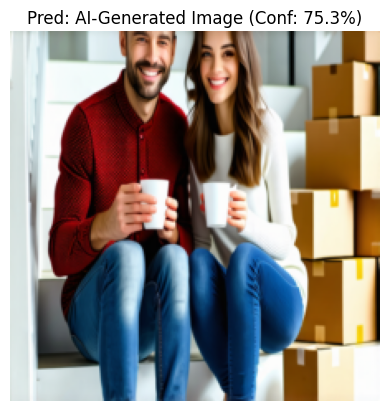

In [87]:
import random
from torchvision import transforms

# 1. Spatial Transform
inference_transform_spatial = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# 2. Frequency Transform
inference_transform_frequency = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# 3. Model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
feature_dim = 256
fusion_hidden_dim = 128
model = HybridModel(feature_dim=feature_dim, fusion_hidden_dim=fusion_hidden_dim, lambda_grl=1.0)
checkpoint = torch.load('/content/hybrid_model.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)

# 4. Pick a random image path from the test dataset
random_idx = random.randint(0, len(test_df) - 1)
test_image_path = test_df.iloc[random_idx]["image_path"]
print(f"Running prediction on: {test_image_path}")

# 5. Run the prediction
custom_image_prediction(
    model=model,
    image_path=test_image_path,
    actual_label=None,  # FIXED: Explicitly set to None since test data has no labels
    class_names=["Human-Created Image", "AI-Generated Image"],
    transform_spatial=inference_transform_spatial,
    transform_frequency=inference_transform_frequency,
    device=device
)

## Gradio Demo

In [88]:
try:
  import gradio as gr
except:
  !pip -qqq install gradio
  import gradio as gr

print(f"Gradio version: {gr.__version__}")


Gradio version: 6.29.0


## Deployment

In [89]:
import shutil
from pathlib import Path

FakeMedia_Detector_path = Path("demos/FakeMedia_Detector/")
if FakeMedia_Detector_path.exists():
  shutil.rmtree(FakeMedia_Detector_path)
  FakeMedia_Detector_path.mkdir(parents=True, exist_ok=True)

else:
  FakeMedia_Detector_path.mkdir(parents=True, exist_ok=True)

### Move the weights into FakeMedia_Detector_path

In [90]:
shutil.move("/content/hybrid_model.pth", "demos/FakeMedia_Detector/hybrid_model.pth")
print("Moved hybrid_model.pth to demos/FakeMedia_Detector/")

Moved hybrid_model.pth to demos/FakeMedia_Detector/


### Creating a folder of example images to use with FakeMedia_Detector model

In [91]:
import shutil
from pathlib import Path

example_images_path = Path("demos/FakeMedia_Detector/examples")
if example_images_path.exists():
  shutil.rmtree(example_images_path)
  example_images_path.mkdir(parents=True, exist_ok=True)

else:
  example_images_path.mkdir(parents=True, exist_ok=True)

FakeMedia_Detector_examples = []
sampled_df = train_df.sample(n=5)

for index, row in sampled_df.iterrows():
    original_path = row["image_path"]

    file_name = Path(original_path).name
    dest_path = example_images_path / file_name
    shutil.copy(original_path, dest_path)
    FakeMedia_Detector_examples.append(str(dest_path))

print(f"Successfully copied 5 examples!")
print(f"Example paths: {FakeMedia_Detector_examples}")

Successfully copied 5 examples!
Example paths: ['demos/FakeMedia_Detector/examples/46c23851d83940edb220c443eebe2ac1.jpg', 'demos/FakeMedia_Detector/examples/b8cb7348b0c5470982f2248043570bba.jpg', 'demos/FakeMedia_Detector/examples/95592c7552da4877a8acd0157d80a0be.jpg', 'demos/FakeMedia_Detector/examples/94cc8a3578df41efb9b561f91dafa2ee.jpg', 'demos/FakeMedia_Detector/examples/40e6ebfb60a64b999cd84cced0305ad5.jpg']


#### class names

In [93]:
class_names = ["Human-Created Image", "AI-Generated Image"]
class_names_path = FakeMedia_Detector_path / "class_names.txt"

with open(class_names_path, "w") as f:
    print(f"[INFO] Saving class names to {class_names_path}")
    f.write("\n".join(class_names))

for index, row in sampled_df.iterrows():
    file_name = Path(row["image_path"]).name
    # Just grab the text label directly from the dataframe
    actual_class_name = row["label"]

    print(f"Image: {file_name} ---> True Class: {actual_class_name}")

[INFO] Saving class names to demos/FakeMedia_Detector/class_names.txt
Image: 46c23851d83940edb220c443eebe2ac1.jpg ---> True Class: AI-Generated Image
Image: b8cb7348b0c5470982f2248043570bba.jpg ---> True Class: Human-Created Image
Image: 95592c7552da4877a8acd0157d80a0be.jpg ---> True Class: Human-Created Image
Image: 94cc8a3578df41efb9b561f91dafa2ee.jpg ---> True Class: AI-Generated Image
Image: 40e6ebfb60a64b999cd84cced0305ad5.jpg ---> True Class: Human-Created Image


### model.py

In [95]:
%%writefile demos/FakeMedia_Detector/model.py
import torch
import torchvision
from torch import nn

def set_seeds(seed: int=42):
    """Sets random sets for torch operations."""
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function

class GradientReversalLayerFn(Function):
    @staticmethod
    def forward(ctx, x, lambda_):
        ctx.lambda_ = lambda_
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        grad_input = grad_output.neg() * ctx.lambda_
        return grad_input, None

class BaseFeatureExtractor(nn.Module):
    def __init__(self, input_channels, feature_dim=256):
        super().__init__()

        self.conv1 = nn.Conv2d(input_channels, 64, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2, 2)

        self.conv4 = nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1)
        self.bn4 = nn.BatchNorm2d(512)
        self.pool4 = nn.MaxPool2d(2, 2)

        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, feature_dim)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        x = self.pool4(F.relu(self.bn4(self.conv4(x))))
        x = self.adaptive_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc(x)))
        return x

class SpatialBranch(BaseFeatureExtractor):
    def __init__(self, feature_dim=256):
        super().__init__(input_channels=3, feature_dim=feature_dim)

class FrequencyBranch(BaseFeatureExtractor):
    def __init__(self, feature_dim=256):
        super().__init__(input_channels=1, feature_dim=feature_dim)

class GatedFusionModule(nn.Module):
    def __init__(self, feature_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.feature_dim = feature_dim

        self.att_weight_spatial = nn.Parameter(torch.ones(feature_dim))
        self.att_weight_freq = nn.Parameter(torch.ones(feature_dim))

        self.fc1 = nn.Linear(feature_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, spatial_features, frequency_features):
        att_s = torch.sigmoid(self.att_weight_spatial)
        att_f = torch.sigmoid(self.att_weight_freq)
        spatial_weighted = spatial_features * att_s
        frequency_weighted = frequency_features * att_f

        combined_features = torch.cat((spatial_weighted, frequency_weighted), dim=1)

        x = self.dropout(F.relu(self.fc1(combined_features)))
        output = self.fc2(x)

        return output, x

class AdversarialDiscriminator(nn.Module):
    def __init__(self, input_size: int, hidden_dim: int = 64, num_domains: int = 1):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, num_domains)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

class HybridModel(nn.Module):
    def __init__(self, feature_dim=256, fusion_hidden_dim=128, disc_hidden_dim=64, lambda_grl=0.1, use_adversarial=True, num_domains=1):
        super().__init__()
        self.use_adversarial = use_adversarial
        self.lambda_grl = lambda_grl

        self.spatial_branch = SpatialBranch(feature_dim)
        self.frequency_branch = FrequencyBranch(feature_dim)
        self.gated_fusion = GatedFusionModule(feature_dim, fusion_hidden_dim)

        if self.use_adversarial:
            self.domain_discriminator = AdversarialDiscriminator(fusion_hidden_dim, disc_hidden_dim, num_domains)

    def forward(self, spatial_input, frequency_input):
        spatial_features = self.spatial_branch(spatial_input)
        frequency_features = self.frequency_branch(frequency_input)

        main_task_output, intermediate_features = self.gated_fusion(spatial_features, frequency_features)

        if self.use_adversarial:
            reversed_features = GradientReversalLayerFn.apply(intermediate_features, self.lambda_grl)
            domain_task_output = self.domain_discriminator(reversed_features)
            return main_task_output, domain_task_output

        return main_task_output

# ==========================================
# Testing and Verification
# ==========================================

def get_fft_representation(rgb_batch):
    """
    Properly converts an RGB image batch to a 1-channel log-magnitude FFT spectrum.
    """
    gray = (0.2989 * rgb_batch[:, 0:1, :, :]) + (0.5870 * rgb_batch[:, 1:2, :, :]) + (0.1140 * rgb_batch[:, 2:3, :, :])

    fft = torch.fft.fft2(gray, norm="ortho")
    fft_shift = torch.fft.fftshift(fft, dim=(-2, -1))

    magnitude = torch.abs(fft_shift)
    log_magnitude = torch.log(magnitude + 1e-8)

    return log_magnitude

if __name__ == "__main__":
    feature_dim = 256
    fusion_hidden_dim = 128

    spatial_input = torch.randn(4, 3, 224, 224)
    frequency_input = get_fft_representation(spatial_input)

    print("--- Testing Baseline Model (No Discriminator) ---")
    baseline_model = HybridModel(use_adversarial=False)
    main_output = baseline_model(spatial_input, frequency_input)
    print("Main Task Output Shape:", main_output.shape)

    print("\n--- Testing Domain-Adversarial Model ---")
    adv_model = HybridModel(use_adversarial=True, lambda_grl=0.1, num_domains=4)
    main_output, domain_output = adv_model(spatial_input, frequency_input)

    print("Main Task Output Shape:", main_output.shape)
    print("Domain Task Output Shape:", domain_output.shape)

Writing demos/FakeMedia_Detector/model.py


### app.py

In [98]:
%%writefile demos/FakeMedia_Detector/app.py
# 1. Imports and class names setup
import gradio as gr
import os
import torch
from torchvision import transforms
from model import HybridModel
from timeit import default_timer as timer
from typing import Tuple, Dict
from PIL import Image

# Setup class names
with open("class_names.txt", "r") as f:
    class_names = [label.strip() for label in f.readlines()]

# 2. Model and transform preparation
# Setup transforms
transform_spatial = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

transform_frequency = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Initialize model
model = HybridModel(feature_dim=256, fusion_hidden_dim=128, lambda_grl=1.0)

# Load saved weights
model.load_state_dict(torch.load("hybrid_model.pth", map_location=torch.device("cpu")))
model.eval()

# 3. predict function
def predict(img) -> Tuple[Dict, float]:
    # start a timer
    start_time = timer()

    # transform input image for spatial and frequency branches
    spatial_img = transform_spatial(img).unsqueeze(0)
    freq_img = transform_frequency(img).unsqueeze(0)

    # put model into eval mode, make prediction
    model.eval()
    with torch.inference_mode():
        class_output, _ = model(spatial_img, freq_img)

        # Binary classification (sigmoid instead of softmax)
        pred_prob = torch.sigmoid(class_output).squeeze().item()

    # create pred label and prob dict
    # class_names[1] is Fake/AI, class_names[0] is Real/Human
    pred_dict = {
        class_names[1]: float(pred_prob),
        class_names[0]: float(1.0 - pred_prob)
    }

    # calculate pred time
    end_time = timer()
    pred_time = round(end_time - start_time, 4)

    # return pred dict and pred time
    return pred_dict, pred_time

# 4. Gradio app interface
# Create title, description, and article
title = "Fake Media Detector "
description = "A Hybrid Spatial-Frequency neural network to classify Real vs AI-Generated images."
article = "Created for detecting synthetic media using dual-branch feature extraction."

# Create example list
example_list = [["examples/" + example] for example in os.listdir("examples/")]

# Create the Gradio demo
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=[
        gr.Label(num_top_classes=2, label="Predictions"),
        gr.Number(label="Prediction time (s)")
    ],
    examples=example_list,
    title=title,
    description=description,
    article=article
)

# Launch the demooo!
if __name__ == "__main__":
    demo.launch()

Writing demos/FakeMedia_Detector/app.py


In [99]:
%%writefile demos/FakeMedia_Detector/requirements.txt
torch==2.6.0
torchvision==0.21.0
gradio==5.41.0

Overwriting demos/FakeMedia_Detector/requirements.txt


In [102]:
!cd demos/FakeMedia_Detector/ && zip -r ../FakeMedia_Detector.zip * -x "*.pyc" "*.ipynb" "*__pycache__" "*ipynb_checkpoints*"

  adding: app.py (deflated 57%)
  adding: class_names.txt (deflated 16%)
  adding: examples/ (stored 0%)
  adding: examples/b8cb7348b0c5470982f2248043570bba.jpg (deflated 0%)
  adding: examples/46c23851d83940edb220c443eebe2ac1.jpg (deflated 2%)
  adding: examples/95592c7552da4877a8acd0157d80a0be.jpg (deflated 2%)
  adding: examples/40e6ebfb60a64b999cd84cced0305ad5.jpg (deflated 3%)
  adding: examples/94cc8a3578df41efb9b561f91dafa2ee.jpg (deflated 0%)
  adding: hybrid_model.pth (deflated 8%)
  adding: model.py (deflated 73%)
  adding: requirements.txt (deflated 8%)


In [103]:
try:
  from google.colab import files
  files.download("demos/FakeMedia_Detector.zip")
except:
  print(f"Not running in Google Colab, can not run google.colab.files.download(), please download manually.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>